# How the robot decides

This notebook shows how `controller.py` turns what the detector saw into a move: the zones in
the picture, the move for every ball position, the 8 scenes of the fake video with each decision
drawn on, and the rules that aren't about the ball. Every decision here comes from the real
`controller.decide`, so if the rules change, this notebook shows the new behavior or stops with
an error.

To look at real footage, set `SOURCE` to a folder recorded with `demo.py --record`. The fake
video gets August's ball and goal presets, since it shows August's field; a recording gets
`robocar_config.json`, set up for Build Day's yellow cones and gray carpet.

In [1]:
# "synthetic" is the fake field video; a recording folder works too, e.g. "../recordings/run1".
SOURCE = "synthetic"

In [2]:
import csv
import json
import sys
from dataclasses import replace
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

# The notebook runs from prep/notebooks/; prep/ is the folder that holds robocar_config.json.
PREP = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "robocar_config.json").exists())
sys.path.insert(0, str(PREP))

from detector import ColorDetector, ColorVision, DetectorConfig
from tools import make_synthetic_video as syn

CONFIG = json.loads((PREP / "robocar_config.json").read_text())
PRESETS = json.loads((PREP / "detector_presets.json").read_text())
if SOURCE == "synthetic":
    # The fake video shows August's field (a white goal on a green floor), so it gets August's
    # presets; a recording gets robocar_config.json, set up for Build Day's cones and carpet.
    BALL = DetectorConfig.from_dict(PRESETS["white_ball"])
    GOAL = DetectorConfig.from_dict(PRESETS["white_goal"])
else:
    BALL = DetectorConfig.from_dict(CONFIG["ball"])
    GOAL = DetectorConfig.from_dict(CONFIG["goal"])
plt.rcParams.update({"figure.dpi": 90, "axes.titlesize": 10})


def load_frames(source):
    """BGR pictures, plus the true ball and goal positions when the source is the fake video."""
    if source == "synthetic":
        return syn.render(seed=7)
    folder = Path(source)
    with (folder / "frames.csv").open(newline="") as fh:
        names = [row["file"] for row in csv.DictReader(fh)]
    return [cv2.imread(str(folder / name)) for name in names], None


def rgb(image_bgr):
    return cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)


frames, truth = load_frames(SOURCE)
print(f"{len(frames)} frames from {SOURCE}")

from controller import Action, ControllerConfig, Observation, RunState, decide, new_run, observation_from

CC = ControllerConfig.from_dict(CONFIG["controller"], stale_after_ms=CONFIG["stream"]["stale_after_ms"])
VISION = ColorVision(BALL, GOAL)
W, H = 320, 240


def decide_fresh(obs, now=0.0):
    """One decision from a fresh run, like watch-only mode: no earlier moves, misses or pushes."""
    return decide(obs, new_run(now), CC, now)[0]

141 frames from synthetic


## 1. The zones in the picture

A few numbers from `robocar_config.json` split the picture. The center band is 24 px either side
of the middle: outside it the robot steers toward the ball. A ball whose center is below 65% of
the height counts as near, so the approach slows down. Below 82% it counts as close, and the
robot starts lining up the goal and pushing. A big enough ball counts as well: a radius of
28 px for near and 42 px for close.

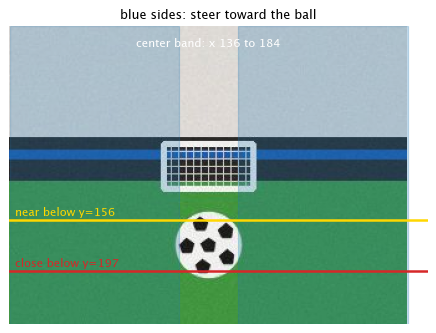

In [3]:
picture = frames[min(48, len(frames) - 1)]
band_left, band_right = W / 2 - CC.center_band_px, W / 2 + CC.center_band_px
near_y, close_y = CC.slow_y_frac * H, CC.close_y_frac * H

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.imshow(rgb(picture))
ax.axvspan(0, band_left, color="tab:blue", alpha=0.25)
ax.axvspan(band_right, W, color="tab:blue", alpha=0.25)
ax.axhline(near_y, color="gold", linewidth=2)
ax.axhline(close_y, color="tab:red", linewidth=2)
ax.text(4, near_y - 4, f"near below y={near_y:.0f}", color="gold", fontsize=9)
ax.text(4, close_y - 4, f"close below y={close_y:.0f}", color="tab:red", fontsize=9)
ax.text(W / 2, 16, f"center band: x {band_left:.0f} to {band_right:.0f}", color="white", ha="center", fontsize=9)
ax.set_title("blue sides: steer toward the ball")
ax.axis("off")
plt.show()

## 2. The move for every ball position

Here the controller is asked about a ball at every point of the floor. The ball grows as it comes
closer, the way it does in the fake video: a radius of 7 px at y = 145, 44 px at y = 205. On the
left the goal is straight ahead; on the right it is off to the left, where a close ball makes
the robot step around it (ORBIT) before pushing.

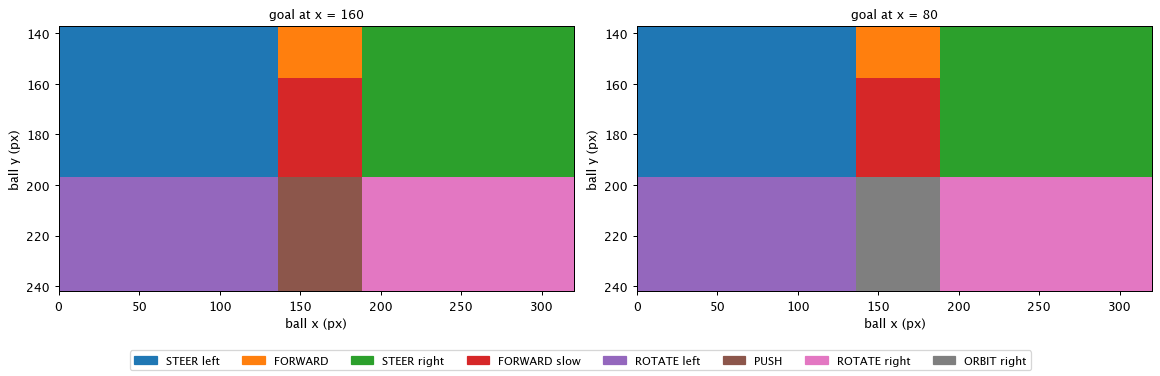

In [4]:
def label(decision):
    if decision.action is Action.FORWARD:
        return "FORWARD slow" if "near" in decision.reason else "FORWARD"
    if decision.action in (Action.STEER, Action.ROTATE, Action.ORBIT):
        return f"{decision.action.value} {decision.direction.replace('rotate_', '')}"
    return decision.action.value


xs = np.arange(0, W, 4)
ys = np.arange(137, H, 3)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
names = []
for ax, goal_x in zip(axes, (160.0, 80.0)):
    grid = np.zeros((len(ys), len(xs)), dtype=int)
    for i, y in enumerate(ys):
        r = float(np.clip(7 + (y - 145) * 37 / 60, 4, 60))
        for j, x in enumerate(xs):
            obs = Observation(frame_time=0.0, frame_seq=1, width=W, height=H, ball_found=True,
                              ball_x=float(x), ball_y=float(y), ball_radius=r,
                              ball_touches_bottom=y + r >= H, goal_found=True, goal_x=goal_x)
            name = label(decide_fresh(obs))
            if name not in names:
                names.append(name)
            grid[i, j] = names.index(name)
    ax.imshow(grid, cmap="tab10", vmin=0, vmax=9, aspect="auto",
              extent=(xs[0], xs[-1] + 4, ys[-1] + 3, ys[0]), interpolation="nearest")
    ax.set_title(f"goal at x = {goal_x:.0f}")
    ax.set_xlabel("ball x (px)")
    ax.set_ylabel("ball y (px)")
handles = [plt.Rectangle((0, 0), 1, 1, color=plt.cm.tab10(k)) for k in range(len(names))]
fig.legend(handles, names, loc="lower center", ncol=len(names), fontsize=9)
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()
assert "ORBIT right" in names, "a close ball with the goal off to the left should make the robot step around it"

## 3. The 8 scenes, with each decision

One picture from the middle of each scene of the fake video, with what the detector found and
what the controller decided, each from a fresh start like watch-only mode. On the fake video
each scene has a known right answer, so they are checked.

Look at `moving_to_center`: the goal's yellow box has swallowed the ball too, because both are
white and the goal's search band reaches down to the ball. The decision is still right, since a
far ball is steered by its own position, but it is the merge to watch for near the goal mouth on
Saturday, where the goal's position does matter.

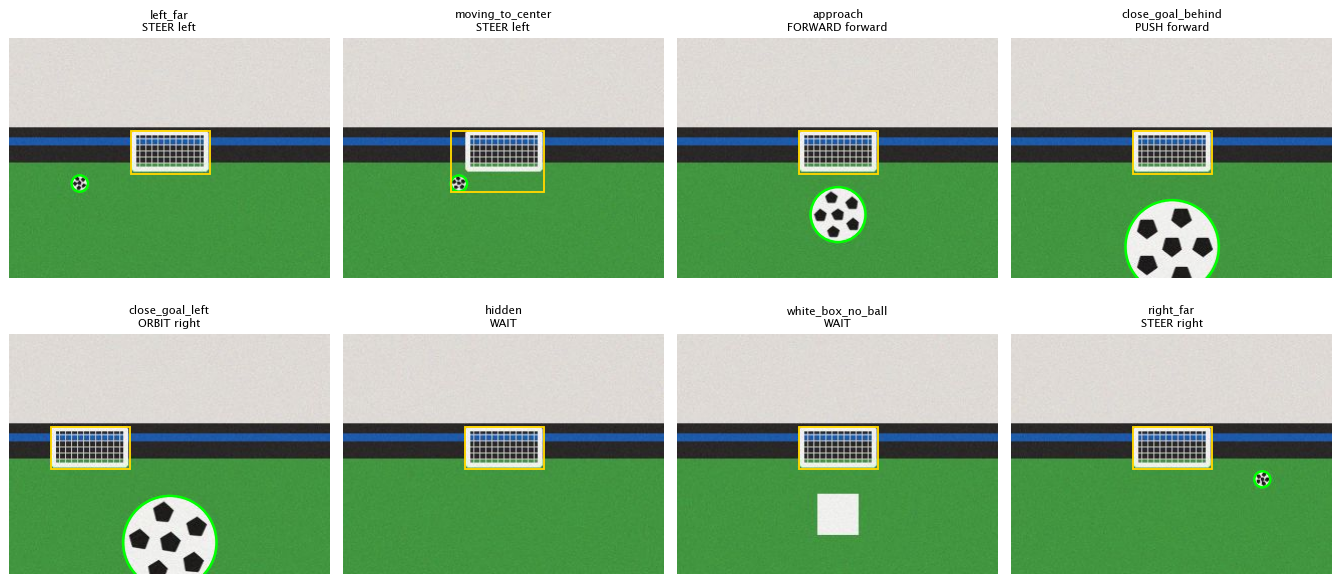

In [5]:
EXPECTED = {
    "left_far": ("STEER", "left"),
    "moving_to_center": ("STEER", "left"),
    "approach": ("FORWARD", "forward"),
    "close_goal_behind": ("PUSH", "forward"),
    "close_goal_left": ("ORBIT", "right"),
    "hidden": ("WAIT", "stop"),
    "white_box_no_ball": ("WAIT", "stop"),
    "right_far": ("STEER", "right"),
}
if truth:
    scenes = {}
    for t in truth:
        scenes.setdefault(t["scene"], []).append(t["frame"])
    picks = [(name, idx[len(idx) // 2]) for name, idx in scenes.items()]
else:
    picks = [(f"frame {i}", i) for i in np.linspace(0, len(frames) - 1, 8).astype(int)]

fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, (name, i) in zip(axes.flat, picks):
    seen = VISION.observe(frames[i], 0.0)
    decision = decide_fresh(observation_from(seen, 0.0, 1, True, ""))
    ax.imshow(rgb(frames[i]))
    if seen.ball.found:
        ax.add_patch(plt.Circle((seen.ball.x, seen.ball.y), seen.ball.radius, fill=False, color="lime", linewidth=2))
    if seen.goal.found:
        g = seen.goal
        ax.add_patch(plt.Rectangle((g.x - g.width / 2, g.y - g.height / 2), g.width, g.height, fill=False, color="gold", linewidth=1.5))
    move = f"{decision.action.value} {decision.direction}" if decision.moves else decision.action.value
    ax.set_title(f"{name}\n{move}", fontsize=9)
    ax.axis("off")
    if name in EXPECTED:
        assert (decision.action.value, decision.direction) == EXPECTED[name], (name, decision.describe())
plt.tight_layout()
plt.show()

## 4. The rules that aren't about the ball

Before the controller looks at the ball, it checks the run itself: is the picture fresh, is the
time up, has the robot just moved. Each row below is one situation, sent through the real
`decide()`. Times are in seconds, as in the run loop.

In [6]:
now = 100.0
stale_s = CC.max_frame_age_ms / 1000  # stream.stale_after_ms in the settings
misses_to_end = CC.miss_frames_to_end  # controller.miss_frames_to_end in the settings
limit_s = CC.run_time_limit_s  # controller.run_time_limit_s in the settings
push_limit = CC.max_pushes  # controller.max_pushes in the settings
ball = dict(ball_found=True, ball_x=160.0, ball_y=150.0, ball_radius=8.0)
fresh = dict(frame_time=now - 0.05, frame_seq=20, width=W, height=H)
cases = [
    (f"the newest picture is {stale_s + 0.1:.1f} s old", dict(fresh, frame_time=now - stale_s - 0.1, **ball), new_run(now - 5), "STOP"),
    ("the camera feed reports a stall", dict(fresh, stream_ok=False, stream_reason=f"no new frame for {CC.max_frame_age_ms:.0f} ms", **ball), new_run(now - 5), "STOP"),
    (f"the {limit_s:g} s run time is used up", dict(fresh, **ball), new_run(now - limit_s - 1), "DONE"),
    ("the picture came 50 ms after the last move", dict(fresh, frame_time=now - 0.01, **ball),
     RunState(started_at=now - 5, last_move_end=now - 0.06, move_end_seq=18), "WAIT"),
    ("only 1 new frame since the last move", dict(fresh, frame_seq=19, **ball),
     RunState(started_at=now - 5, last_move_end=now - 1.0, move_end_seq=18), "WAIT"),
    ("the ball is missing once", dict(fresh), new_run(now - 5), "WAIT"),
    (f"the ball is missing {misses_to_end} times in a row", dict(fresh), RunState(started_at=now - 5, misses=misses_to_end - 1), "STOP"),
    ("the ball is gone after a push", dict(fresh), RunState(started_at=now - 5, misses=misses_to_end - 1, pushes=1), "DONE"),
    (f"{push_limit} pushes are done", dict(fresh, **ball), RunState(started_at=now - 5, pushes=push_limit), "DONE"),
    ("all fine: a centered, far ball", dict(fresh, **ball), new_run(now - 5), "FORWARD"),
]
for situation, fields, state, expected in cases:
    decision, _ = decide(Observation(**fields), state, CC, now)
    print(f"{situation:<44} {decision.action.value:<8} {decision.reason}")
    assert decision.action.value == expected, (situation, decision.describe())

the newest picture is 3.1 s old              STOP     newest frame is 3100 ms old (limit 3000 ms)
the camera feed reports a stall              STOP     camera feed problem: no new frame for 3000 ms
the 45 s run time is used up                 DONE     time limit of 45 s reached
the picture came 50 ms after the last move   WAIT     frame arrived too soon after the last move; waiting for a fresh one
only 1 new frame since the last move         WAIT     waiting for frame 20; the camera may still be sending older pictures
the ball is missing once                     WAIT     ball not seen (1 of 5); holding still
the ball is missing 5 times in a row         STOP     ball lost for 5 frames in a row
the ball is gone after a push                DONE     ball gone after 1 push(es): attempt finished
8 pushes are done                            DONE     attempt finished after 8 pushes; ball now at x=160
all fine: a centered, far ball               FORWARD  ball centered and far: approach
